In [213]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [214]:
df = pd.read_csv(r"/Users/sanketgarg/Downloads/Telco-Customer-Churn.csv")

In [215]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [216]:
df.shape

(7043, 21)

In [217]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [218]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [219]:
(df["Churn"].value_counts()/df.shape[0])*100

Churn
No     73.463013
Yes    26.536987
Name: count, dtype: float64

<function matplotlib.pyplot.show(close=None, block=None)>

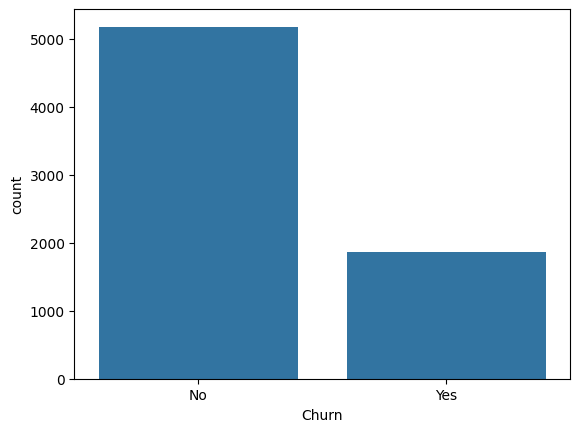

In [220]:
sns.countplot(data = df,x="Churn")
plt.show

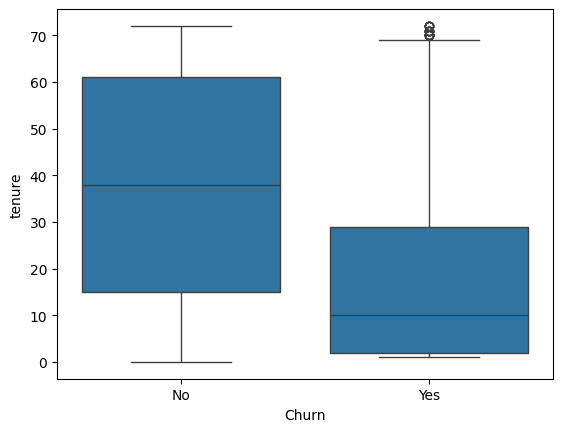

In [221]:
sns.boxplot(data=df, x="Churn", y="tenure")
plt.show()

In [222]:
df.groupby("Churn")["tenure"].median()

Churn
No     38.0
Yes    10.0
Name: tenure, dtype: float64

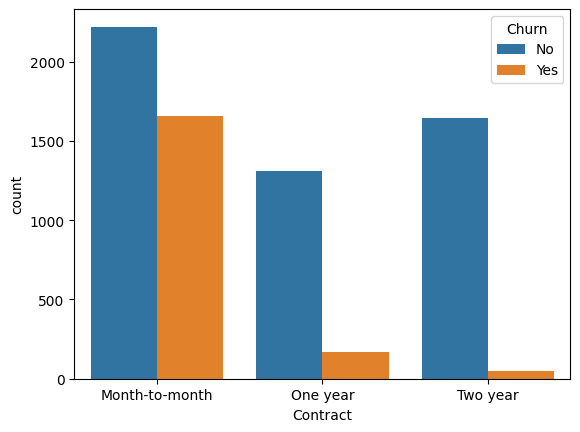

In [223]:
sns.countplot(data=df, x="Contract", hue="Churn")
plt.show()

In [224]:
pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


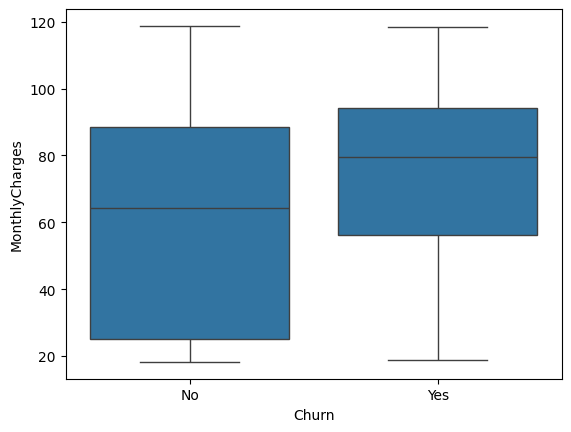

In [225]:
sns.boxplot(data = df, x = "Churn", y = "MonthlyCharges" )
plt.show()

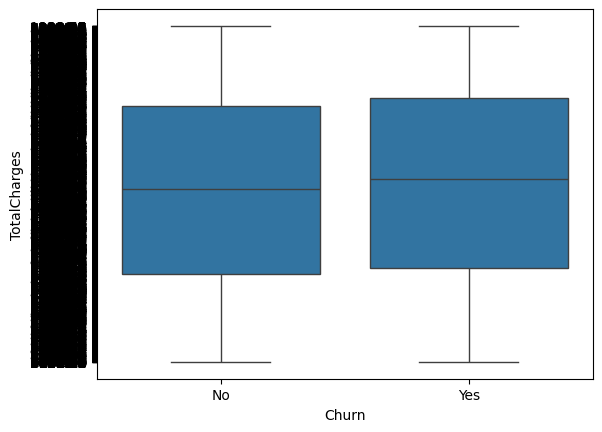

In [226]:
sns.boxplot(data = df, x = "Churn", y = "TotalCharges" )
plt.show()

In [227]:
df["TotalCharges"].dtype

dtype('O')

In [228]:
df["TotalCharges"].head(10)

0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: object

In [229]:
pd.to_numeric(df["TotalCharges"], errors="coerce").isna().sum()

11

In [230]:
df[pd.to_numeric(df["TotalCharges"], errors="coerce").isna()][["tenure", "TotalCharges", "Churn"]]

,tenure,TotalCharges,Churn
488,0,,No
753,0,,No
936,0,,No
1082,0,,No
1340,0,,No
3331,0,,No
3826,0,,No
4380,0,,No
5218,0,,No
6670,0,,No


In [231]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [232]:
df["TotalCharges"].isna().sum()

11

In [233]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [234]:
df["TotalCharges"].isna().sum()

0

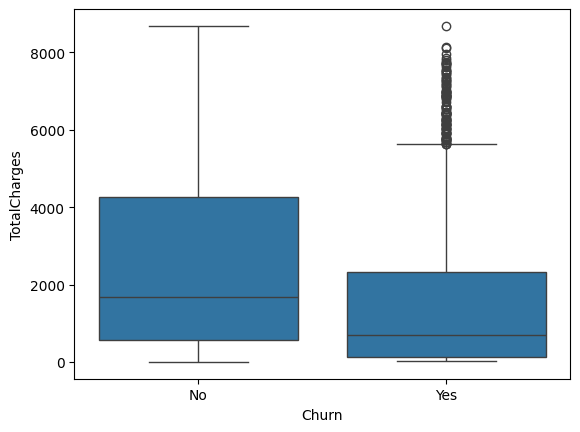

In [235]:
sns.boxplot(data=df, x="Churn", y="TotalCharges")
plt.show()

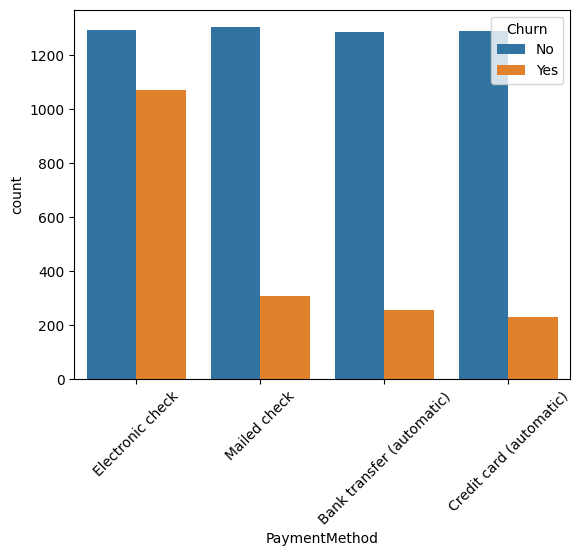

In [236]:
sns.countplot(data=df, x="PaymentMethod", hue="Churn")
plt.xticks(rotation=45)
plt.show()

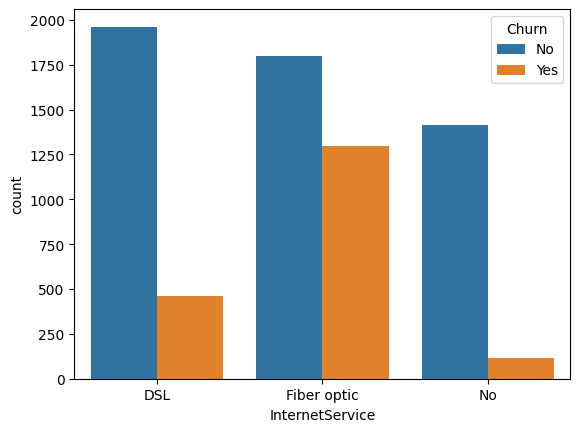

In [237]:
sns.countplot(data=df, x="InternetService", hue="Churn")
plt.show()


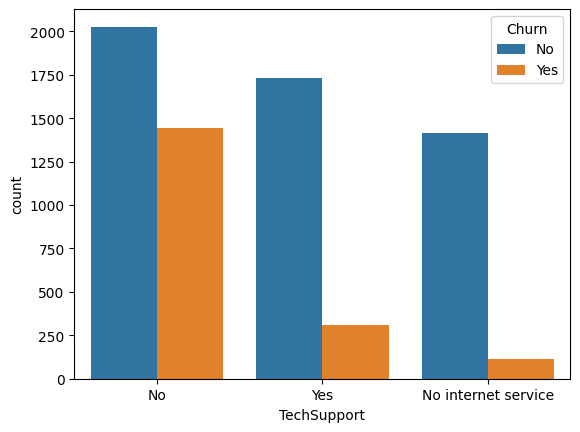

In [238]:
sns.countplot(data=df, x="TechSupport", hue="Churn")
plt.show()

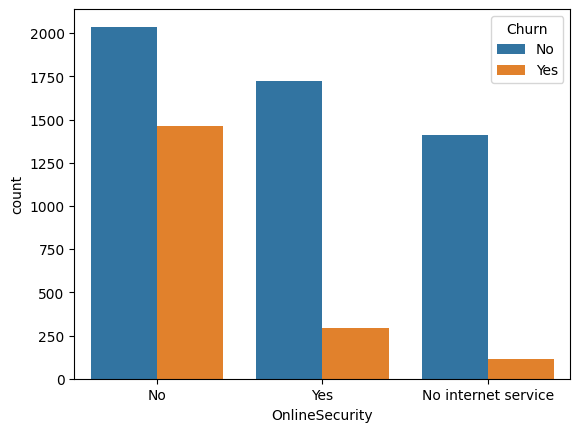

In [239]:
sns.countplot(data=df, x="OnlineSecurity", hue="Churn")
plt.show()

In [240]:
df["DeviceProtection"].dtype

dtype('O')

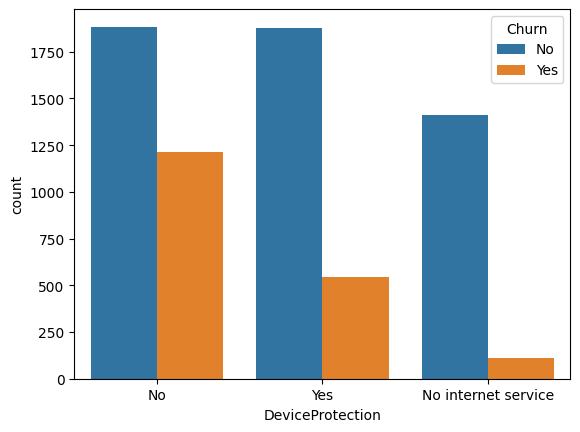

In [241]:
sns.countplot(data=df, x="DeviceProtection", hue ="Churn")
plt.show()

In [242]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [243]:
df.duplicated().sum()

0

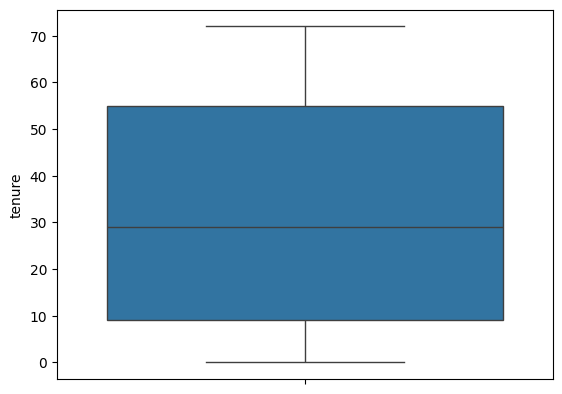

In [244]:
sns.boxplot(data=df, y="tenure")
plt.show()

In [245]:
df = df.drop("customerID", axis=1)

In [246]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

In [247]:
from sklearn.model_selection import train_test_split

In [248]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = 0.2, random_state = 42,stratify = y)

In [249]:
X_train.shape

(5634, 19)

In [250]:
X_train.dtypes

gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
dtype: object

In [251]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

In [252]:
categorical_cols = X_train.select_dtypes(include="object").columns
numerical_cols = X_train.select_dtypes(exclude="object").columns

In [253]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

In [254]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [255]:
X_train_processed.shape


(5634, 45)

In [256]:

X_test_processed.shape


(1409, 45)

In [257]:
from sklearn.dummy import DummyClassifier

In [258]:
dummy = DummyClassifier(strategy="most_frequent")

In [259]:
dummy.fit(X_train_processed, y_train)

DummyClassifier(strategy='most_frequent')

In [260]:
y_pred_dummy = dummy.predict(X_test_processed)

In [261]:
from sklearn.metrics import accuracy_score

In [262]:
dummy_accuracy = accuracy_score(y_test, y_pred_dummy)

In [263]:
from sklearn.metrics import precision_score, recall_score, f1_score
dummy_precision = precision_score(y_test, y_pred_dummy, pos_label="Yes")
dummy_recall = recall_score(y_test, y_pred_dummy, pos_label="Yes")
dummy_f1 = f1_score(y_test, y_pred_dummy, pos_label="Yes")

In [264]:
from sklearn.linear_model import LogisticRegression

In [265]:
log_reg = LogisticRegression(max_iter=1000)

In [266]:
log_reg.fit(X_train_processed, y_train)

LogisticRegression(max_iter=1000)

In [267]:
y_pred_log = log_reg.predict(X_test_processed)

In [268]:
log_accuracy = accuracy_score(y_test, y_pred_log)

In [269]:
from sklearn.metrics import confusion_matrix, classification_report

In [270]:
confusion_matrix(y_test, y_pred_log)

array([[926, 109],
       [165, 209]])

In [271]:


log_precision = precision_score(y_test, y_pred_log, pos_label="Yes")
log_recall = recall_score(y_test, y_pred_log, pos_label="Yes")
log_f1 = f1_score(y_test, y_pred_log, pos_label="Yes")

print("Precision:", log_precision)
print("Recall:", log_recall)
print("F1-score:", log_f1)

Precision: 0.6572327044025157
Recall: 0.5588235294117647
F1-score: 0.6040462427745664


In [272]:
from sklearn.neighbors import KNeighborsClassifier

In [273]:
knn = KNeighborsClassifier(n_neighbors=5)

In [274]:
knn.fit(X_train_processed, y_train)

KNeighborsClassifier()

In [275]:
y_pred_knn = knn.predict(X_test_processed)

In [276]:
confusion_matrix(y_test,y_pred_knn)

array([[861, 174],
       [159, 215]])

In [277]:
knn_precision = precision_score(y_test, y_pred_knn, pos_label="Yes")
knn_recall = recall_score(y_test, y_pred_knn, pos_label="Yes")
knn_f1 = f1_score(y_test, y_pred_knn, pos_label="Yes")

print("Precision:", knn_precision)
print("Recall:", knn_recall)
print("F1-score:", knn_f1)

Precision: 0.5526992287917738
Recall: 0.5748663101604278
F1-score: 0.563564875491481


In [278]:
knn_accuracy = accuracy_score(y_test, y_pred_knn)

In [279]:
from sklearn.tree import DecisionTreeClassifier

In [280]:
dt = DecisionTreeClassifier(random_state= 42)

In [281]:
dt.fit(X_train_processed, y_train)

DecisionTreeClassifier(random_state=42)

In [282]:
y_pred_dt = dt.predict(X_test_processed)

In [283]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)

In [284]:
dt_precision = precision_score(y_test, y_pred_dt, pos_label="Yes")
dt_recall = recall_score(y_test, y_pred_dt, pos_label="Yes")
dt_f1 = f1_score(y_test, y_pred_dt, pos_label="Yes")

print("Precision:", dt_precision)
print("Recall:", dt_recall)
print("F1-score:", dt_f1)

Precision: 0.4713541666666667
Recall: 0.4839572192513369
F1-score: 0.47757255936675463


In [285]:
from sklearn.ensemble import RandomForestClassifier

In [286]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [287]:
rf.fit(X_train_processed, y_train)

RandomForestClassifier(random_state=42)

In [288]:
y_pred_rf = rf.predict(X_test_processed)

In [289]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)

In [290]:
rf_precision = precision_score(y_test, y_pred_rf, pos_label="Yes")
rf_recall = recall_score(y_test, y_pred_rf, pos_label="Yes")
rf_f1 = f1_score(y_test, y_pred_rf, pos_label="Yes")

print("Precision:", rf_precision)
print("Recall:", rf_recall)
print("F1-score:", rf_f1)

Precision: 0.6082474226804123
Recall: 0.4732620320855615
F1-score: 0.5323308270676692


In [291]:
from sklearn.svm import SVC

In [292]:
svm = SVC(kernel="rbf", random_state=42)

In [293]:
svm.fit(X_train_processed, y_train)

SVC(random_state=42)

In [294]:
y_pred_svc = svm.predict(X_test_processed)

In [295]:
svm_precision = precision_score(y_test, y_pred_svc, pos_label="Yes")
svm_recall = recall_score(y_test, y_pred_svc, pos_label="Yes")
svm_f1 = f1_score(y_test, y_pred_svc, pos_label="Yes")

print("Precision:", svm_precision)
print("Recall:", svm_recall)
print("F1-score:", svm_f1)

Precision: 0.6418439716312057
Recall: 0.4839572192513369
F1-score: 0.551829268292683


In [296]:
svm_accuracy = accuracy_score(y_test, y_pred_svc)

In [297]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN", "Decision Tree", "Random Forest", "SVM"],
    "Accuracy": [log_accuracy, knn_accuracy, dt_accuracy, rf_accuracy, svm_accuracy],
    "Precision": [log_precision, knn_precision, dt_precision, rf_precision, svm_precision],
    "Recall": [log_recall, knn_recall, dt_recall, rf_recall, svm_recall],
    "F1": [log_f1, knn_f1, dt_f1, rf_f1, svm_f1]
})

comparison

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.805536,0.657233,0.558824,0.604046
1,KNN,0.763662,0.552699,0.574866,0.563565
2,Decision Tree,0.718950,0.471354,0.483957,0.477573
3,Random Forest,0.779276,0.608247,0.473262,0.532331
4,SVM,0.791341,0.641844,0.483957,0.551829


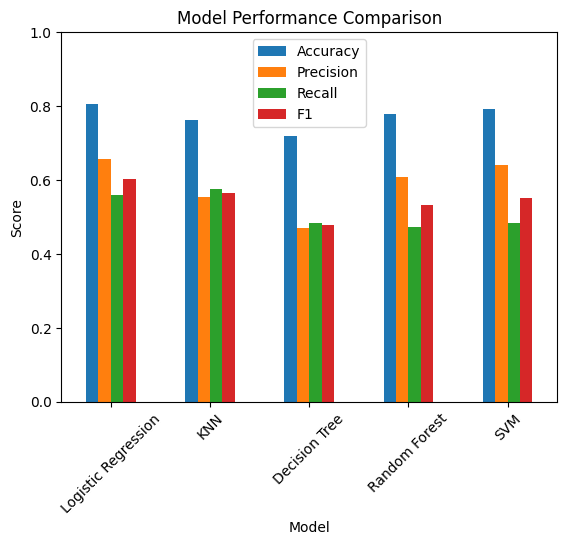

In [298]:
comparison.plot(
    x="Model",
    y=["Accuracy", "Precision", "Recall", "F1"],
    kind="bar"
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=45)
plt.ylim(0, 1)
plt.legend()
plt.show()

In [299]:
from sklearn.linear_model import LogisticRegression

C_values = [0.01, 0.1, 1, 10, 100]

for c in C_values:
    model = LogisticRegression(C=c, max_iter=1000)
    model.fit(X_train_processed, y_train)
    
    y_pred = model.predict(X_test_processed)
    
    f1 = f1_score(y_test, y_pred, pos_label="Yes")
    
    print("C =", c, "F1 =", f1)

C = 0.01 F1 = 0.5692541856925418
C = 0.1 F1 = 0.591304347826087
C = 1 F1 = 0.6040462427745664
C = 10 F1 = 0.6031746031746031
C = 100 F1 = 0.5936599423631124


In [304]:
from sklearn.metrics import make_scorer, f1_score
from sklearn.model_selection import cross_val_score

f1_scorer = make_scorer(f1_score, pos_label="Yes")

log_reg_cv = LogisticRegression(max_iter=1000)

cv_scores = cross_val_score(
    log_reg_cv,
    X_train_processed,
    y_train,
    cv=5,
    scoring=f1_scorer
)

print("F1 scores:", cv_scores)
print("Mean F1:", cv_scores.mean())

F1 scores: [0.65082267 0.58472998 0.59668508 0.57809695 0.57960644]
Mean F1: 0.5979882242724168


In [305]:
from sklearn.model_selection import cross_val_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    "SVM": SVC(kernel="rbf", random_state=42)
}

cv_results = {}

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train_processed,
        y_train,
        cv=5,
        scoring=f1_scorer
    )
    
    cv_results[name] = scores.mean()
    print(name, "Mean F1:", scores.mean())

Logistic Regression Mean F1: 0.5979882242724168
KNN Mean F1: 0.5447077599147735
Decision Tree Mean F1: 0.47560497590205475
Random Forest Mean F1: 0.5509481299151664
SVM Mean F1: 0.5723210814263275


In [306]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_processed, y_train)

y_prob = log_reg.predict_proba(X_test_processed)[:, 1]

In [307]:
import numpy as np

thresholds = np.arange(0.1, 1.0, 0.05)

for threshold in thresholds:
    y_pred_threshold = np.where(
        y_prob >= threshold,
        "Yes",
        "No"
    )
    
    f1 = f1_score(
        y_test,
        y_pred_threshold,
        pos_label="Yes"
    )
    
    print(
        "Threshold:", round(threshold, 2),
        "F1:", round(f1, 4)
    )

Threshold: 0.1 F1: 0.5682
Threshold: 0.15 F1: 0.5938
Threshold: 0.2 F1: 0.6043
Threshold: 0.25 F1: 0.6165
Threshold: 0.3 F1: 0.615
Threshold: 0.35 F1: 0.614
Threshold: 0.4 F1: 0.6143
Threshold: 0.45 F1: 0.6085
Threshold: 0.5 F1: 0.604
Threshold: 0.55 F1: 0.5501
Threshold: 0.6 F1: 0.5146
Threshold: 0.65 F1: 0.4356
Threshold: 0.7 F1: 0.2955
Threshold: 0.75 F1: 0.1359
Threshold: 0.8 F1: 0.0517
Threshold: 0.85 F1: 0.0053
Threshold: 0.9 F1: 0.0
Threshold: 0.95 F1: 0.0


In [308]:
from sklearn.model_selection import cross_val_predict

log_reg_cv = LogisticRegression(max_iter=1000)

y_train_proba = cross_val_predict(
    log_reg_cv,
    X_train_processed,
    y_train,
    cv=5,
    method="predict_proba"
)[:, 1]

In [309]:
import numpy as np
from sklearn.metrics import f1_score

thresholds = np.arange(0.1, 0.91, 0.01)

f1_scores = []

for threshold in thresholds:
    y_pred = np.where(
        y_train_proba >= threshold,
        "Yes",
        "No"
    )
    
    f1 = f1_score(
        y_train,
        y_pred,
        pos_label="Yes"
    )
    
    f1_scores.append(f1)

best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]
best_f1 = f1_scores[best_index]

print("Best threshold:", best_threshold)
print("Best CV F1:", best_f1)

Best threshold: 0.3299999999999999
Best CV F1: 0.6356005788712011


In [310]:
log_reg = LogisticRegression(max_iter=1000)

log_reg.fit(X_train_processed, y_train)

y_test_proba = log_reg.predict_proba(X_test_processed)[:, 1]

y_pred_final = np.where(
    y_test_proba >= best_threshold,
    "Yes",
    "No"
)

In [311]:


print("Accuracy:", accuracy_score(y_test, y_pred_final))
print("Precision:", precision_score(y_test, y_pred_final, pos_label="Yes"))
print("Recall:", recall_score(y_test, y_pred_final, pos_label="Yes"))
print("F1:", f1_score(y_test, y_pred_final, pos_label="Yes"))

Accuracy: 0.7615330021291696
Precision: 0.538
Recall: 0.7192513368983957
F1: 0.6155606407322655


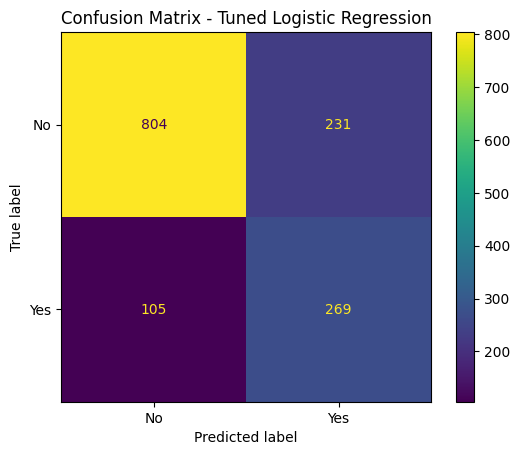

[[804 231]
 [105 269]]


In [313]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred_final,
    labels=["No", "Yes"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

disp.plot()
plt.title("Confusion Matrix - Tuned Logistic Regression")
plt.show()

print(cm)

In [314]:
feature_names = preprocessor.get_feature_names_out()

coefficients = log_reg.coef_[0]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

feature_importance = feature_importance.sort_values(
    "Coefficient",
    ascending=False
)

feature_importance.head(10)

,Feature,Coefficient
16,cat__InternetService_Fiber optic,0.634195
36,cat__Contract_Month-to-month,0.582883
3,num__TotalCharges,0.536253
35,cat__StreamingMovies_Yes,0.200938
32,cat__StreamingTV_Yes,0.200481
43,cat__PaymentMethod_Electronic check,0.197867
18,cat__OnlineSecurity_No,0.156279
27,cat__TechSupport_No,0.131503
14,cat__MultipleLines_Yes,0.104649
0,num__SeniorCitizen,0.053449


In [315]:
feature_importance.sort_values(
    "Coefficient",
    ascending=True
).head(10)

,Feature,Coefficient
1,num__tenure,-1.257539
38,cat__Contract_Two year,-0.776594
15,cat__InternetService_DSL,-0.648646
2,num__MonthlyCharges,-0.591863
39,cat__PaperlessBilling_No,-0.343227
31,cat__StreamingTV_No internet service,-0.300104
34,cat__StreamingMovies_No internet service,-0.300104
17,cat__InternetService_No,-0.300104
25,cat__DeviceProtection_No internet service,-0.300104
19,cat__OnlineSecurity_No internet service,-0.300104
